# Tome 8, Appendix A: Euclid Revisited (Python companion)

Exercises first, solutions at the end. We test the theorems of the chapter on thousands of random triangles: Euler's line, the nine-point circle, Napoleon, Morley, Euler's inequality $R\ge2r$, Routh's formula and the Gauss–Lucas theorem. Points are Python complex numbers, as in the chapter. We use `numpy`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import cmath, math
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(1)

def random_triangle():
    # three random points of the unit circle: O = 0 and R = 1, as in the chapter
    t = np.sort(rng.uniform(0, 2 * np.pi, 3))
    return [complex(np.cos(x), np.sin(x)) for x in t]   # counterclockwise

## Exercises

**P1.1 (★) Euler and the nine points.** For $10^4$ random triangles inscribed in the unit circle, compute $G$ and $H$ from their definitions (intersect two medians and two altitudes, without using $h=a+b+c$), and check Theorem 1.4 and Theorem 1.5: report the largest error.

**P1.2 (★★) Morley by brute force.** Write a function that intersects the angle trisectors of a triangle and returns the three Morley points. On $10^4$ random triangles, check that the Morley triangle is equilateral and that its side is $8R\sin\frac A3\sin\frac B3\sin\frac C3$ (Theorem 1.11). What happens if you use the trisectors of the *exterior* angles?

**P1.3 (★) Napoleon, outside and inside.** Check Theorem 1.10 on random triangles, then build the equilateral triangles *inwards* and check that their centres also form an equilateral triangle. Compare the difference of the areas of the outer and inner Napoleon triangles with the area of $ABC$.

**P1.4 (★) Euler's inequality.** For random triangles compute $R$, $r$ and $OI$, check $OI^2=R(R-2r)$ (Exercise 1.3), and draw the histogram of $r/R$. How often is $r/R>0.45$?

**P1.5 (★★) Routh.** For random ratios $x,y,z>0$, divide the sides of a triangle with $BD/DC=x$, $CE/EA=y$, $AF/FB=z$, intersect the cevians and compare the area of the inner triangle with the formula of the solution of Exercise 1.10.

**P1.6 (★) Gauss–Lucas.** Plot the roots of a random polynomial of degree $8$, their convex hull, and the roots of its derivative (Exercise 1.9). For a cubic, check Marden's theorem: the roots of $p'$ are the foci of the ellipse tangent to the sides at their midpoints, so the sum of their distances to each midpoint is the same.

## Solutions

### P1.1
**How to find it.** Intersecting two lines $p+t\,u$ and $q+s\,v$ is a $2\times2$ linear system. Perpendicular directions are multiplications by $i$.

In [2]:
def meet(p, u, q, v):
    # intersection of the lines p + t u and q + s v
    M = np.array([[u.real, -v.real], [u.imag, -v.imag]])
    t, s = np.linalg.solve(M, [q.real - p.real, q.imag - p.imag])
    return p + t * u

err_line = err_circle = 0
for _ in range(10000):
    a, b, c = random_triangle()
    g = meet(a, (b + c) / 2 - a, b, (c + a) / 2 - b)
    h = meet(a, 1j * (c - b), b, 1j * (a - c))
    n = h / 2
    err_line = max(err_line, abs(h - 3 * g))
    feet = [meet(a, 1j * (c - b), b, c - b), meet(b, 1j * (a - c), c, a - c), meet(c, 1j * (b - a), a, b - a)]
    pts = feet + [(b + c) / 2, (c + a) / 2, (a + b) / 2, (a + h) / 2, (b + h) / 2, (c + h) / 2]
    err_circle = max(err_circle, max(abs(abs(z - n) - 0.5) for z in pts))
print("max |H - 3G| =", err_line, "  max | |P - N| - 1/2 | =", err_circle)

max |H - 3G| = 7.50970630872506e-12   max | |P - N| - 1/2 | = 3.0964120156795616e-12


Both errors are rounding errors, of order $10^{-12}$ at worst (thin triangles make the linear systems ill-conditioned).

### P1.2
**How to find it.** At a vertex $V$ with neighbours $U$ and $W$, rotate the direction $V\to W$ towards $V\to U$ by one and two thirds of the angle. The rotation is $e^{i\theta}$ with the sign of the angle from $W-V$ to $U-V$.

In [3]:
def trisector(V, W, U, k):
    # ray from V, starting from the direction VW and turning towards VU by k/3 of the angle WVU
    phi = cmath.phase((U - V) / (W - V))      # signed angle from VW to VU
    return (W - V) * cmath.exp(1j * k * phi / 3)

def morley(a, b, c):
    P = meet(b, trisector(b, c, a, 1), c, trisector(c, b, a, 1))   # adjacent to BC
    Q = meet(c, trisector(c, a, b, 1), a, trisector(a, c, b, 1))   # adjacent to CA
    Rm = meet(a, trisector(a, b, c, 1), b, trisector(b, a, c, 1))  # adjacent to AB
    return P, Q, Rm

def angle(V, U, W):
    return abs(cmath.phase((W - V) / (U - V)))

worst = worst_formula = 0
for _ in range(10000):
    a, b, c = random_triangle()
    P, Q, Rm = morley(a, b, c)
    s = [abs(P - Q), abs(Q - Rm), abs(Rm - P)]
    A, B, Cg = angle(a, b, c), angle(b, c, a), angle(c, a, b)
    worst = max(worst, (max(s) - min(s)) / max(s))
    worst_formula = max(worst_formula, abs(s[0] - 8 * math.sin(A / 3) * math.sin(B / 3) * math.sin(Cg / 3)))
print("largest relative deviation from equilateral:", worst)
print("largest error in the side formula (R = 1):", worst_formula)

# exterior trisectors: at each vertex trisect the exterior angle (between VW and the extension of UV beyond V)
def morley_ext(a, b, c):
    def tri(V, W, U, k):
        phi = cmath.phase((V - U) / (W - V))     # exterior angle, from VW to the extension of UV
        return (W - V) * cmath.exp(1j * k * phi / 3)
    P = meet(b, tri(b, c, a, 1), c, tri(c, b, a, 1))
    Q = meet(c, tri(c, a, b, 1), a, tri(a, c, b, 1))
    Rm = meet(a, tri(a, b, c, 1), b, tri(b, a, c, 1))
    return P, Q, Rm
a, b, c = random_triangle()
P, Q, Rm = morley_ext(a, b, c)
print("exterior version, sides:", abs(P - Q), abs(Q - Rm), abs(Rm - P))

largest relative deviation from equilateral: 4.867551437010612e-11
largest error in the side formula (R = 1): 5.967448757360216e-16
exterior version, sides: 1.530413150676448 1.530413150676448 1.530413150676448


The interior Morley triangle is equilateral to about $10^{-12}$ in every trial, and the side formula holds. The exterior trisectors also give an equilateral triangle: Morley's theorem has 18 equilateral triangles in all when one allows exterior trisectors (the original theorem is one of them), a fact also covered by Connes' proof.

### P1.3
**How to find it.** Lemma 1.9 gives the third vertex: for the outward triangle on $BC$, $p=-\omega c-\omega^2 b$; inwards, the orientation is reversed, so $p=-\omega b-\omega^2c$.

In [4]:
w = cmath.exp(2j * math.pi / 3)
def area(a, b, c):
    return ((b - a).conjugate() * (c - a)).imag / 2

def napoleon(a, b, c, outward=True):
    def third(u, v):     # apex of the equilateral triangle on the side u -> v (triangle counterclockwise)
        return -w * v - w * w * u if outward else -w * u - w * w * v
    return [(u + v + third(u, v)) / 3 for u, v in ((b, c), (c, a), (a, b))]

worst = 0
for _ in range(10000):
    a, b, c = random_triangle()
    out, inn = napoleon(a, b, c), napoleon(a, b, c, False)
    for T in (out, inn):
        s = [abs(T[0] - T[1]), abs(T[1] - T[2]), abs(T[2] - T[0])]
        worst = max(worst, max(s) - min(s))
    d = abs(area(*out)) - abs(area(*inn)) - area(a, b, c)
    worst = max(worst, abs(d))
print("all checks hold up to", worst)

all checks hold up to 6.661338147750939e-16


Both Napoleon triangles are equilateral, and the area of the outer one minus the area of the inner one equals the area of $ABC$, a classical complement to Napoleon's theorem that you can prove with the formula of Proposition 1.1.

### P1.4
**How to find it.** With $R=1$: $r=2\,\text{area}/\text{perimeter}$, and the incentre is the average of the vertices weighted by the opposite sides.

max |OI^2 - R(R - 2r)| = 6.661338147750939e-16   fraction with r/R > 0.45: 0.07615


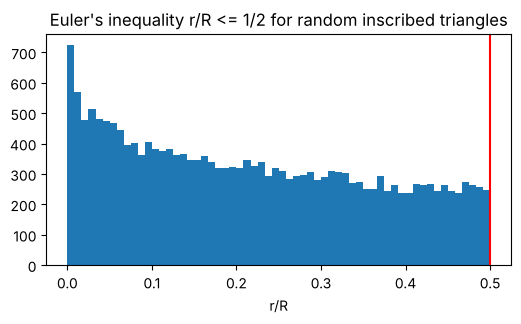

In [5]:
ratios, worst = [], 0
for _ in range(20000):
    a, b, c = random_triangle()
    la, lb, lc = abs(b - c), abs(c - a), abs(a - b)
    I = (la * a + lb * b + lc * c) / (la + lb + lc)
    r = 2 * area(a, b, c) / (la + lb + lc)
    worst = max(worst, abs(abs(I) ** 2 - (1 - 2 * r)))
    ratios.append(r)
ratios = np.array(ratios)
print("max |OI^2 - R(R - 2r)| =", worst, "  fraction with r/R > 0.45:", np.mean(ratios > 0.45))
plt.figure(figsize=(6, 3)); plt.hist(ratios, bins=60); plt.axvline(0.5, color="r")
plt.xlabel("r/R"); plt.title("Euler's inequality r/R <= 1/2 for random inscribed triangles"); plt.show()

The ratio never exceeds $\frac12$ and approaches it only for nearly equilateral triangles, which are rare among random ones (a few per cent above $0.45$).

### P1.5
**How to find it.** A point dividing $BC$ with $BD/DC=x$ is $D=\frac{B+xC}{1+x}$.

In [6]:
def routh_formula(x, y, z):
    return (x * y * z - 1) ** 2 / ((x * y + x + 1) * (y * z + y + 1) * (z * x + z + 1))

worst = 0
for _ in range(5000):
    a, b, c = random_triangle()
    x, y, z = rng.uniform(0.1, 5, 3)
    D, E, F = (b + x * c) / (1 + x), (c + y * a) / (1 + y), (a + z * b) / (1 + z)
    P, Q, Rm = meet(a, D - a, b, E - b), meet(b, E - b, c, F - c), meet(c, F - c, a, D - a)
    worst = max(worst, abs(abs(area(P, Q, Rm)) / area(a, b, c) - routh_formula(x, y, z)))
print("largest error in Routh's formula:", worst, "  x = y = z = 1/2 gives", routh_formula(.5, .5, .5))

largest error in Routh's formula: 3.1200320105284618e-12   x = y = z = 1/2 gives 0.14285714285714285


### P1.6
**How to find it.** `np.roots` and `np.polyder`; for Marden, the ellipse with foci $f_1,f_2$ is the set where $|z-f_1|+|z-f_2|$ is constant, so this sum must be the same at the three midpoints.

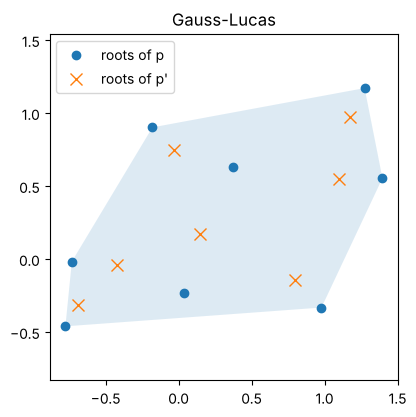

|m - f1| + |m - f2| at the three midpoints: [np.float64(1.091321906612), np.float64(1.091321906612), np.float64(1.091321906612)]


In [7]:
from matplotlib.patches import Polygon
z = rng.standard_normal(8) + 1j * rng.standard_normal(8)
p = np.poly(z)
crit = np.roots(np.polyder(p))
ang = np.angle(z - z.mean()); hull_order = np.argsort(ang)
plt.figure(figsize=(4.5, 4.5))
# convex hull by the monotone chain algorithm
pts = sorted((q.real, q.imag) for q in z)
def half(points):
    h = []
    for P in points:
        while len(h) >= 2 and (h[-1][0] - h[-2][0]) * (P[1] - h[-2][1]) - (h[-1][1] - h[-2][1]) * (P[0] - h[-2][0]) <= 0:
            h.pop()
        h.append(P)
    return h
hull = half(pts)[:-1] + half(pts[::-1])[:-1]
plt.gca().add_patch(Polygon(hull, alpha=0.15))
plt.plot(z.real, z.imag, "o", label="roots of p"); plt.plot(crit.real, crit.imag, "x", ms=9, label="roots of p'")
plt.legend(); plt.axis("equal"); plt.title("Gauss-Lucas"); plt.show()

a, b, c = random_triangle()
f1, f2 = np.roots(np.polyder(np.poly([a, b, c])))
print("|m - f1| + |m - f2| at the three midpoints:",
      [round(abs(m - f1) + abs(m - f2), 12) for m in ((b + c) / 2, (c + a) / 2, (a + b) / 2)])

The three sums agree to 12 digits: the midpoints of the sides lie on one ellipse with foci at the critical points, as Marden's theorem says (tangency to the sides is the other half of the theorem).